<a href="https://colab.research.google.com/github/ChamiruGajasinghe/NEXORA_CNN/blob/lochana-training/Lochana_Training_Evaluation.ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EN3150 Assignment 03- NEXORA

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print(tf.__version__)

2.21.0


In [ ]:
# image sizes
image_height = 64
image_width = 64

#this will use later during training
batch_size = 32
epochs = 20

print("Image size:", image_height, "x", image_width)

Image size: 64 x 64


In [ ]:
import random

seed = 42
random.seed(seed)
np.random.seed(seed)
tf.random.set_seed(seed)

print("Seed set to", seed)

Seed set to 42


## Data Preparation


In [ ]:
import os
from sklearn.model_selection import train_test_split

### Loading the RealWaste dataset

In [ ]:
# downloading the RealWaste dataset from UCI
!wget -q --show-progress https://archive.ics.uci.edu/static/public/908/realwaste.zip -O realwaste.zip

realwaste.zip           [            <=>     ] 656.65M  3.47MB/s    in 5m 6s   


In [ ]:
# extracting the dataset
!unzip -oq realwaste.zip -d realwaste_data

In [ ]:
# extracted files
print(os.listdir("realwaste_data"))

['realwaste-main']


In [ ]:
dataset_path = "realwaste_data/realwaste-main/RealWaste"

print(os.listdir(dataset_path))

['Glass', 'Cardboard', 'Metal', 'Food Organics', 'Textile Trash', 'Plastic', 'Paper', 'Miscellaneous Trash', 'Vegetation']


In [ ]:
# get class names
class_names = os.listdir(dataset_path)
class_names.sort()

print("Classes:", class_names)
print("Number of classes:", len(class_names))

Classes: ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']
Number of classes: 9


In [ ]:
# count images in each class
total_images = 0

for class_name in class_names:
    class_path = os.path.join(dataset_path, class_name)
    image_count = len(os.listdir(class_path))

    print(class_name, ":", image_count)
    total_images = total_images + image_count

print("Total images:", total_images)

Cardboard : 461
Food Organics : 411
Glass : 420
Metal : 790
Miscellaneous Trash : 495
Paper : 500
Plastic : 921
Textile Trash : 318
Vegetation : 436
Total images: 4752


### Sample images

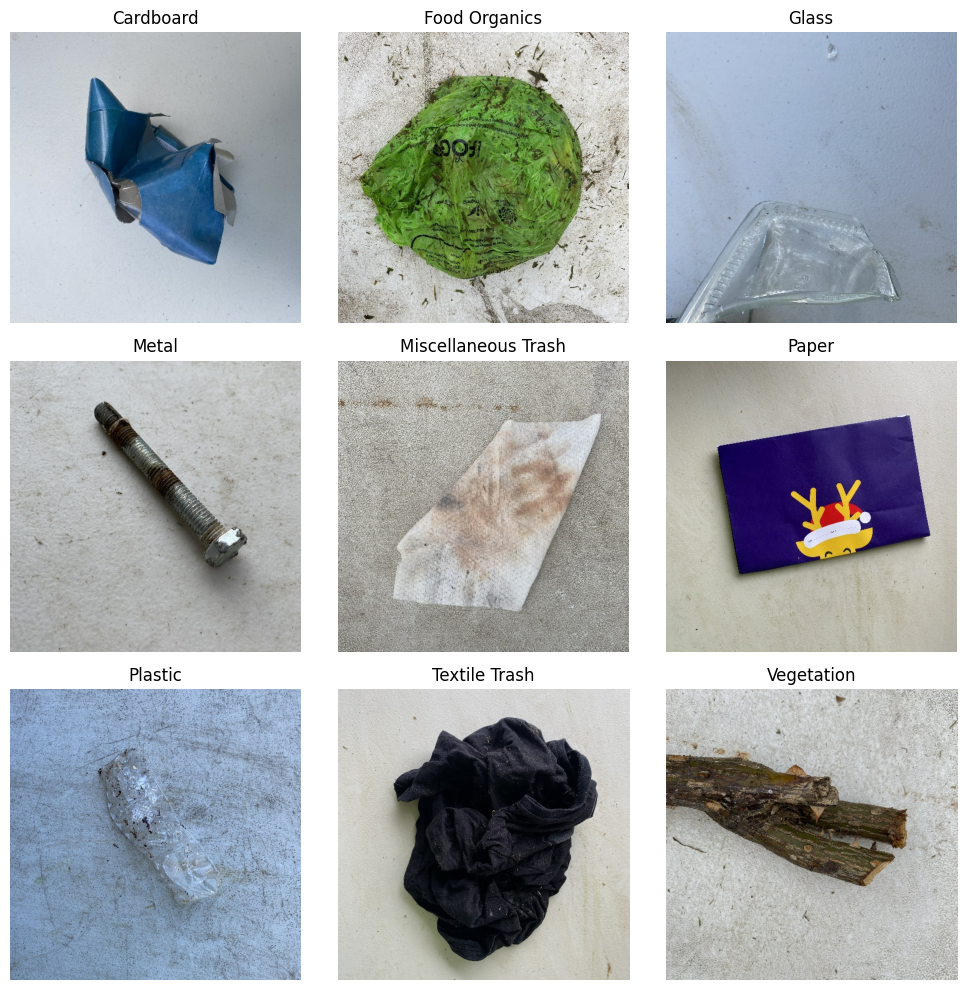

In [ ]:
# show one image from each class
plt.figure(figsize=(10, 10))

for i in range(len(class_names)):
    class_name = class_names[i]
    class_path = os.path.join(dataset_path, class_name)

    image_files = os.listdir(class_path)
    image_name = image_files[0]

    image_path = os.path.join(class_path, image_name)
    image = plt.imread(image_path)

    plt.subplot(3, 3, i + 1)
    plt.imshow(image)
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

### Image paths and labels

In [ ]:
image_paths = []
labels = []

for class_number, class_name in enumerate(class_names):
    class_path = os.path.join(dataset_path, class_name)

    image_files = os.listdir(class_path)
    image_files.sort()

    for image_name in image_files:
        image_path = os.path.join(class_path, image_name)

        image_paths.append(image_path)
        labels.append(class_number)

print("Images:", len(image_paths))
print("Labels:", len(labels))

Images: 4752
Labels: 4752


### Train, validation and test split

In [ ]:
# keep 70% for training
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    image_paths,
    labels,
    test_size=0.30,
    random_state=seed,
    stratify=labels
)

In [ ]:
# divide the remaining 30% equally
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths,
    temp_labels,
    test_size=0.50,
    random_state=seed,
    stratify=temp_labels
)

In [ ]:
print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))
print("Testing images:", len(test_paths))

Training images: 3326
Validation images: 713
Testing images: 713


In [ ]:
print("Training:", round(len(train_paths) / total_images * 100, 2), "%")
print("Validation:", round(len(val_paths) / total_images * 100, 2), "%")
print("Testing:", round(len(test_paths) / total_images * 100, 2), "%")

Training: 69.99 %
Validation: 15.0 %
Testing: 15.0 %


### Image preprocessing

In [ ]:
def load_image(image_path, label):

    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)

    image = tf.image.resize(
        image,
        [image_height, image_width]
    )

    image = tf.cast(image, tf.float32)
    image = image / 255.0

    return image, label

In [ ]:
train_ds = tf.data.Dataset.from_tensor_slices(
    (train_paths, train_labels)
)

train_ds = train_ds.map(load_image)

train_ds = train_ds.shuffle(
    len(train_paths),
    seed=seed
)

train_ds = train_ds.batch(batch_size)

In [ ]:
val_ds = tf.data.Dataset.from_tensor_slices(
    (val_paths, val_labels)
)

val_ds = val_ds.map(load_image)
val_ds = val_ds.batch(batch_size)

In [ ]:
test_ds = tf.data.Dataset.from_tensor_slices(
    (test_paths, test_labels)
)

test_ds = test_ds.map(load_image)
test_ds = test_ds.batch(batch_size)

In [ ]:
for images, batch_labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", batch_labels.shape)

Image batch shape: (32, 64, 64, 3)
Label batch shape: (32,)


In [ ]:
for images, batch_labels in train_ds.take(1):
    print("Minimum value:", tf.reduce_min(images).numpy())
    print("Maximum value:", tf.reduce_max(images).numpy())

Minimum value: 0.0
Maximum value: 1.0


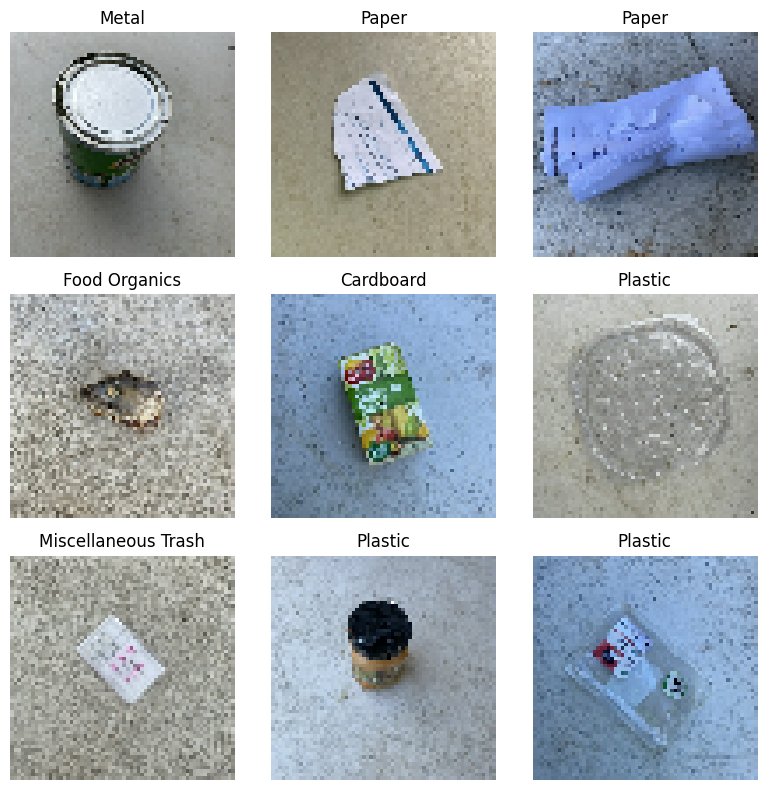

In [ ]:
for images, batch_labels in train_ds.take(1):

    plt.figure(figsize=(8, 8))

    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i])
        plt.title(class_names[batch_labels[i]])
        plt.axis("off")

    plt.tight_layout()
    plt.show()

## Optimizer Selection and Training

In [ ]:

# Optimizers that will be compared
learning_rate = 0.001

def make_optimizer(name):
    if name == "sgd":
        return keras.optimizers.SGD(
            learning_rate=learning_rate
        )

    if name == "momentum":
        return keras.optimizers.SGD(
            learning_rate=learning_rate,
            momentum=0.9
        )

    if name == "adam":
        return keras.optimizers.Adam(
            learning_rate=learning_rate
        )

    raise ValueError(f"Unknown optimizer: {name}")

print("SGD optimizer prepared")
print("SGD with Momentum optimizer prepared")
print("Adam selected as the main optimizer")

SGD optimizer prepared
SGD with Momentum optimizer prepared
Adam selected as the main optimizer


In [ ]:
def train_model(model, optimizer, epochs=20):

    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    start_time = time.time()

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=epochs,
        verbose=1
    )

    end_time = time.time()

    training_time = end_time - start_time

    return history, training_time

Add Exact model A architecture

In [ ]:

def build_model_a():
    model = keras.Sequential([
        layers.Input(shape=(64, 64, 3)),

        layers.Conv2D(
            16, (3, 3),
            activation="relu",
            padding="same"
        ),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(
            32, (3, 3),
            activation="relu",
            padding="same"
        ),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(
            64, (3, 3),
            activation="relu",
            padding="same"
        ),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dense(num_classes, activation="softmax")
    ])

    return model




In [ ]:
num_classes = len(class_names)
print("Number of classes:", num_classes)

Number of classes: 9


In [ ]:
temp_a = build_model_a()
print("Model A parameters:", temp_a.count_params())

Model A parameters: 286377


Add exact Model B architecture


In [ ]:

def ds_block(x, filters, pool=True):
    x = layers.DepthwiseConv2D(
        (3, 3),
        padding="same",
        use_bias=False
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU(max_value=6.0)(x)

    x = layers.Conv2D(
        filters,
        (1, 1),
        use_bias=False
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU(max_value=6.0)(x)

    if pool:
        x = layers.MaxPooling2D((2, 2))(x)

    return x


def build_model_b():
    inputs = keras.Input(shape=(64, 64, 3))

    x = layers.Conv2D(
        16, (3, 3),
        padding="same",
        use_bias=False
    )(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU(max_value=6.0)(x)
    x = layers.MaxPooling2D((2, 2))(x)

    x = ds_block(x, 32, pool=True)
    x = ds_block(x, 64, pool=True)
    x = ds_block(x, 128, pool=True)
    x = ds_block(x, 256, pool=False)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(64)(x)
    x = layers.ReLU(max_value=6.0)(x)

    outputs = layers.Dense(
        num_classes,
        activation="softmax"
    )(x)

    return keras.Model(inputs, outputs)


In [ ]:
temp_b = build_model_b()

trainable_b = sum(
    np.prod(w.shape)
    for w in temp_b.trainable_weights
)

print("Model B trainable parameters:", trainable_b)

Model B trainable parameters: 64617


##Loss curve code


In [ ]:
def plot_loss_curves(history, title):

    plt.figure(figsize=(8, 5))

    plt.plot(
        history.history["loss"],
        label="Training Loss"
    )

    plt.plot(
        history.history["val_loss"],
        label="Validation Loss"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()

In [ ]:
def plot_accuracy_curves(history, title):

    plt.figure(figsize=(8, 5))

    plt.plot(
        history.history["accuracy"],
        label="Training Accuracy"
    )

    plt.plot(
        history.history["val_accuracy"],
        label="Validation Accuracy"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()

##Evaluation code

In [47]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)



def evaluate_model(model):
    test_loss, _ = model.evaluate(
        test_ds,
        verbose=0
    )

    y_true = []
    y_pred = []

    for images, labels in test_ds:
        predictions = model.predict(
            images,
            verbose=0
        )

        predicted_labels = np.argmax(
            predictions,
            axis=1
        )

        y_true.extend(labels.numpy())
        y_pred.extend(predicted_labels)

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    accuracy = accuracy_score(
        y_true, y_pred
    )

    precision = precision_score(
        y_true, y_pred,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_true, y_pred,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_true, y_pred,
        average="weighted",
        zero_division=0
    )

    return (
        y_true, y_pred, test_loss,
        accuracy, precision, recall, f1
    )


##Confusion Matrix

In [ ]:
import seaborn as sns

def plot_confusion_matrix(y_true, y_pred, title):

    cm = confusion_matrix(
        y_true,
        y_pred
    )

    plt.figure(figsize=(10, 8))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.xlabel("Predicted Class")
    plt.ylabel("True Class")
    plt.title(title)
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

##Results

In [ ]:
def print_results(
    accuracy,
    precision,
    recall,
    training_time
):

    print("Test Accuracy :", f"{accuracy:.4f}")
    print("Precision     :", f"{precision:.4f}")
    print("Recall        :", f"{recall:.4f}")
    print("Training Time :", f"{training_time:.2f} seconds")


In [ ]:

num_classes = len(class_names)

print("Number of classes:", num_classes)


Number of classes: 9


In [ ]:
print("Training dataset:", train_ds)
print("Validation dataset:", val_ds)
print("Test dataset:", test_ds)
print("Classes:", class_names)
print("Number of classes:", num_classes)

Training dataset: <_BatchDataset element_spec=(TensorSpec(shape=(None, 64, 64, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>
Validation dataset: <_BatchDataset element_spec=(TensorSpec(shape=(None, 64, 64, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>
Test dataset: <_BatchDataset element_spec=(TensorSpec(shape=(None, 64, 64, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>
Classes: ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']
Number of classes: 9


## Model A Optimizer Experiment


In [ ]:
import time
optimizer_names = ["sgd", "momentum", "adam"]
optimizer_results = {}

for name in optimizer_names:
    print("\nTraining with:", name)

    # Reset random seeds
    random.seed(42)
    np.random.seed(42)
    tf.random.set_seed(42)

    # Build a fresh Model A
    model = build_model_a()

    history, training_time = train_model(
        model,
        make_optimizer(name),
        epochs=20
    )

    best_val_accuracy = max(
        history.history["val_accuracy"]
    )

    best_val_loss = min(
        history.history["val_loss"]
    )

    optimizer_results[name] = {
        "history": history,
        "training_time": training_time,
        "best_val_accuracy": best_val_accuracy,
        "best_val_loss": best_val_loss
    }



Training with: sgd
Epoch 1/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 26s 154ms/step - accuracy: 0.1822 - loss: 2.1829 - val_accuracy: 0.1992 - val_loss: 2.1746
Epoch 2/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 42s 182ms/step - accuracy: 0.1945 - loss: 2.1671 - val_accuracy: 0.1935 - val_loss: 2.1610
Epoch 3/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 23s 154ms/step - accuracy: 0.1939 - loss: 2.1552 - val_accuracy: 0.1935 - val_loss: 2.1513
Epoch 4/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 26s 162ms/step - accuracy: 0.1939 - loss: 2.1471 - val_accuracy: 0.1935 - val_loss: 2.1453
Epoch 5/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 25s 154ms/step - accuracy: 0.1939 - loss: 2.1420 - val_accuracy: 0.1935 - val_loss: 2.1416
Epoch 6/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 28s 154ms/step - accuracy: 0.1939 - loss: 2.1387 - val_accuracy: 0.1935 - val_loss: 2.1388
Epoch 7/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 38s 151ms/step - accuracy: 0.1939 - loss: 2.1359 - val_accuracy: 0.1935 - val_loss: 2.1364
Epoch 8/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 43s 172ms/step - accura

the comparison and select an optimizer


In [ ]:

for name, result in optimizer_results.items():
    print("\n", name)

    print(
        "Best validation accuracy:",
        round(result["best_val_accuracy"], 4)
    )

    print(
        "Best validation loss:",
        round(result["best_val_loss"], 4)
    )

    print(
        "Training time:",
        round(result["training_time"], 2),
        "seconds"
    )

selected_optimizer = max(
    optimizer_results,
    key=lambda name:
        optimizer_results[name]["best_val_accuracy"]
)

print("Selected optimizer:", selected_optimizer)



 sgd
Best validation accuracy: 0.1992
Best validation loss: 2.0981
Training time: 586.17 seconds

 momentum
Best validation accuracy: 0.547
Best validation loss: 1.2932
Training time: 627.28 seconds

 adam
Best validation accuracy: 0.6957
Best validation loss: 0.9951
Training time: 634.54 seconds
Selected optimizer: adam


##Train final model A

In [43]:

random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

final_model_a = build_model_a()

history_a, training_time_a = train_model(
    final_model_a,
    make_optimizer(selected_optimizer),
    epochs=20
)


Epoch 1/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 27s 160ms/step - accuracy: 0.3103 - loss: 1.9003 - val_accuracy: 0.4418 - val_loss: 1.6394
Epoch 2/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 25s 157ms/step - accuracy: 0.4492 - loss: 1.4885 - val_accuracy: 0.5077 - val_loss: 1.4000
Epoch 3/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 25s 160ms/step - accuracy: 0.5225 - loss: 1.3215 - val_accuracy: 0.5273 - val_loss: 1.3310
Epoch 4/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 40s 157ms/step - accuracy: 0.5908 - loss: 1.1502 - val_accuracy: 0.5596 - val_loss: 1.2327
Epoch 5/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 24s 153ms/step - accuracy: 0.6263 - loss: 1.0396 - val_accuracy: 0.6115 - val_loss: 1.1487
Epoch 6/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 26s 171ms/step - accuracy: 0.6597 - loss: 0.9375 - val_accuracy: 0.6452 - val_loss: 1.0702
Epoch 7/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 25s 156ms/step - accuracy: 0.6879 - loss: 0.8738 - val_accuracy: 0.6494 - val_loss: 1.0117
Epoch 8/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 24s 152ms/step - accuracy: 0.7210 - loss: 0

##Train final model B

In [44]:

random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

final_model_b = build_model_b()

history_b, training_time_b = train_model(
    final_model_b,
    make_optimizer(selected_optimizer),
    epochs=20
)


Epoch 1/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 43s 243ms/step - accuracy: 0.3821 - loss: 1.7170 - val_accuracy: 0.1935 - val_loss: 2.2243
Epoch 2/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 41s 242ms/step - accuracy: 0.5301 - loss: 1.3102 - val_accuracy: 0.0884 - val_loss: 2.4961
Epoch 3/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 38s 227ms/step - accuracy: 0.5953 - loss: 1.1199 - val_accuracy: 0.1711 - val_loss: 3.1519
Epoch 4/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 40s 218ms/step - accuracy: 0.6524 - loss: 0.9759 - val_accuracy: 0.2370 - val_loss: 2.6364
Epoch 5/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 30s 206ms/step - accuracy: 0.6687 - loss: 0.8847 - val_accuracy: 0.3871 - val_loss: 2.0713
Epoch 6/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 33s 239ms/step - accuracy: 0.7138 - loss: 0.8108 - val_accuracy: 0.6199 - val_loss: 1.0745
Epoch 7/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 30s 215ms/step - accuracy: 0.7336 - loss: 0.7297 - val_accuracy: 0.4123 - val_loss: 1.9518
Epoch 8/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 30s 205ms/step - accuracy: 0.7637 - loss: 0

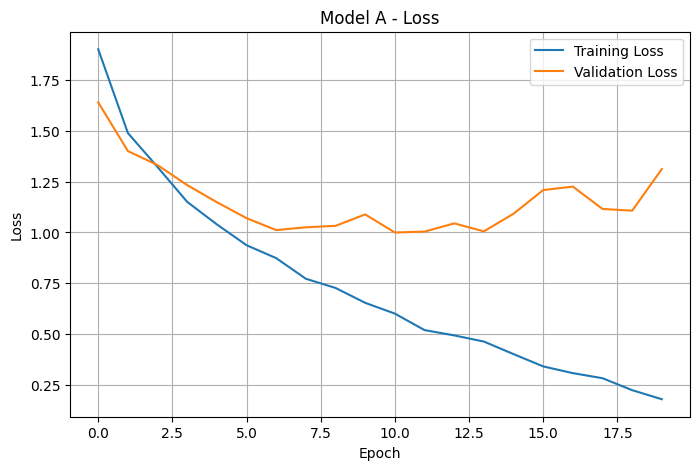

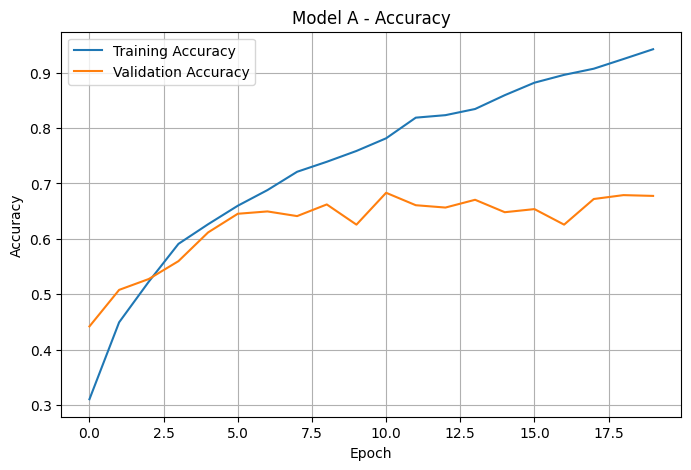

In [45]:
plot_loss_curves(history_a, "Model A - Loss")
plot_accuracy_curves(history_a, "Model A - Accuracy")

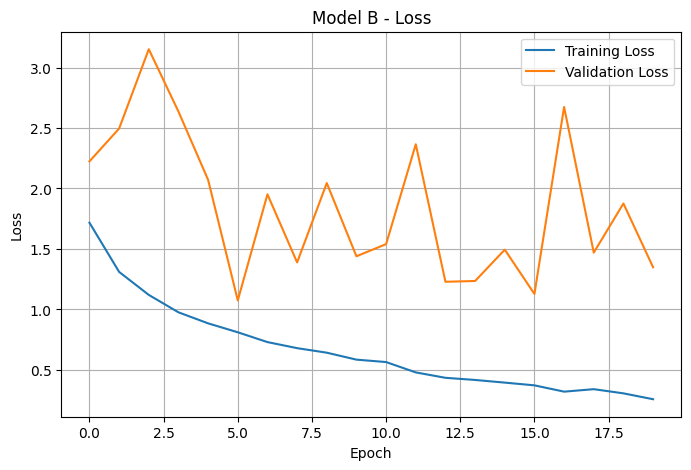

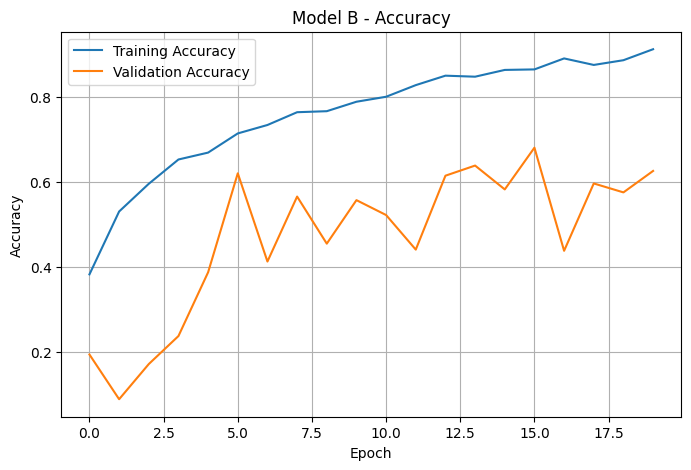

In [46]:
plot_loss_curves(history_b, "Model B - Loss")
plot_accuracy_curves(history_b, "Model B - Accuracy")

##Evaluate model A

In [48]:

(
    y_true_a,
    y_pred_a,
    test_loss_a,
    accuracy_a,
    precision_a,
    recall_a,
    f1_a
) = evaluate_model(final_model_a)

print("Model A")
print("Test loss:", round(test_loss_a, 4))
print("Test accuracy:", round(accuracy_a, 4))
print("Precision:", round(precision_a, 4))
print("Recall:", round(recall_a, 4))
print("F1-score:", round(f1_a, 4))
print(
    "Training time:",
    round(training_time_a, 2),
    "seconds"
)

print(
    classification_report(
        y_true_a,
        y_pred_a,
        labels=list(range(num_classes)),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)


Model A
Test loss: 1.4122
Test accuracy: 0.6452
Precision: 0.6527
Recall: 0.6452
F1-score: 0.6422
Training time: 561.37 seconds
                     precision    recall  f1-score   support

          Cardboard     0.6667    0.6667    0.6667        69
      Food Organics     0.7826    0.5806    0.6667        62
              Glass     0.8409    0.5873    0.6916        63
              Metal     0.6387    0.6441    0.6414       118
Miscellaneous Trash     0.3438    0.2933    0.3165        75
              Paper     0.6914    0.7467    0.7179        75
            Plastic     0.5815    0.7754    0.6646       138
      Textile Trash     0.6923    0.5625    0.6207        48
         Vegetation     0.7910    0.8154    0.8030        65

           accuracy                         0.6452       713
          macro avg     0.6699    0.6302    0.6432       713
       weighted avg     0.6527    0.6452    0.6422       713



##Evaluate model B

In [49]:

(
    y_true_b,
    y_pred_b,
    test_loss_b,
    accuracy_b,
    precision_b,
    recall_b,
    f1_b
) = evaluate_model(final_model_b)

print("Model B")
print("Test loss:", round(test_loss_b, 4))
print("Test accuracy:", round(accuracy_b, 4))
print("Precision:", round(precision_b, 4))
print("Recall:", round(recall_b, 4))
print("F1-score:", round(f1_b, 4))
print(
    "Training time:",
    round(training_time_b, 2),
    "seconds"
)

print(
    classification_report(
        y_true_b,
        y_pred_b,
        labels=list(range(num_classes)),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)


Model B
Test loss: 1.4195
Test accuracy: 0.6045
Precision: 0.6317
Recall: 0.6045
F1-score: 0.5936
Training time: 708.88 seconds
                     precision    recall  f1-score   support

          Cardboard     0.6724    0.5652    0.6142        69
      Food Organics     0.8000    0.4516    0.5773        62
              Glass     0.6897    0.6349    0.6612        63
              Metal     0.5318    0.7797    0.6323       118
Miscellaneous Trash     0.4559    0.4133    0.4336        75
              Paper     0.8750    0.4667    0.6087        75
            Plastic     0.5345    0.6739    0.5962       138
      Textile Trash     0.6111    0.2292    0.3333        48
         Vegetation     0.6966    0.9538    0.8052        65

           accuracy                         0.6045       713
          macro avg     0.6519    0.5743    0.5847       713
       weighted avg     0.6317    0.6045    0.5936       713



Plotting the confusion matrices

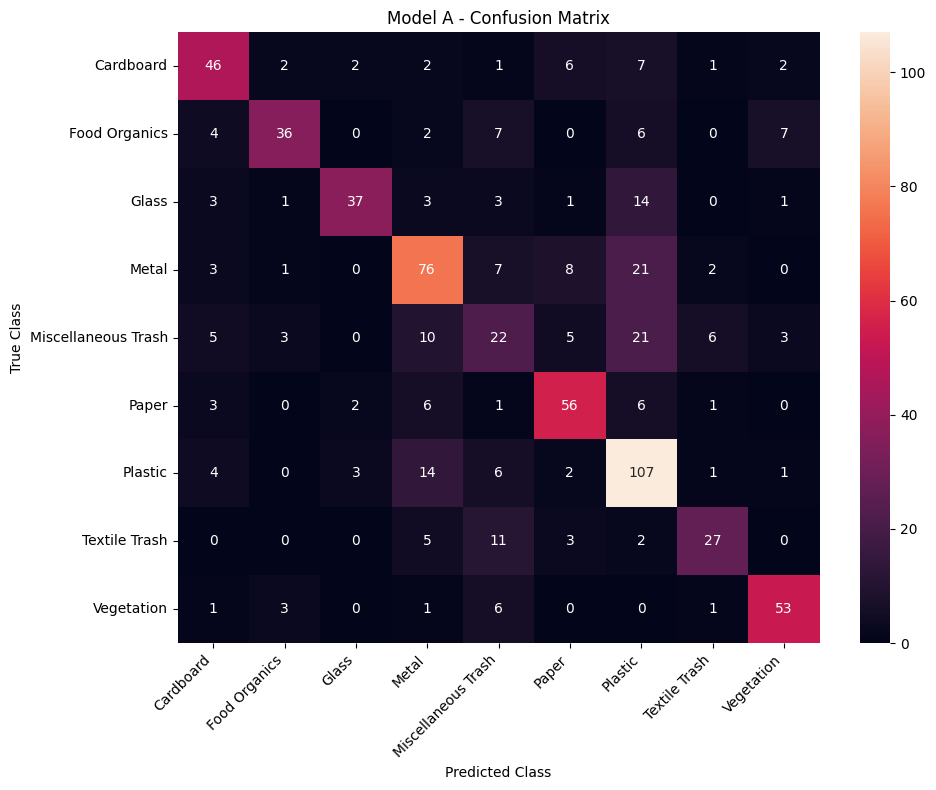

In [50]:
plot_confusion_matrix(
    y_true_a,
    y_pred_a,
    "Model A - Confusion Matrix"
)

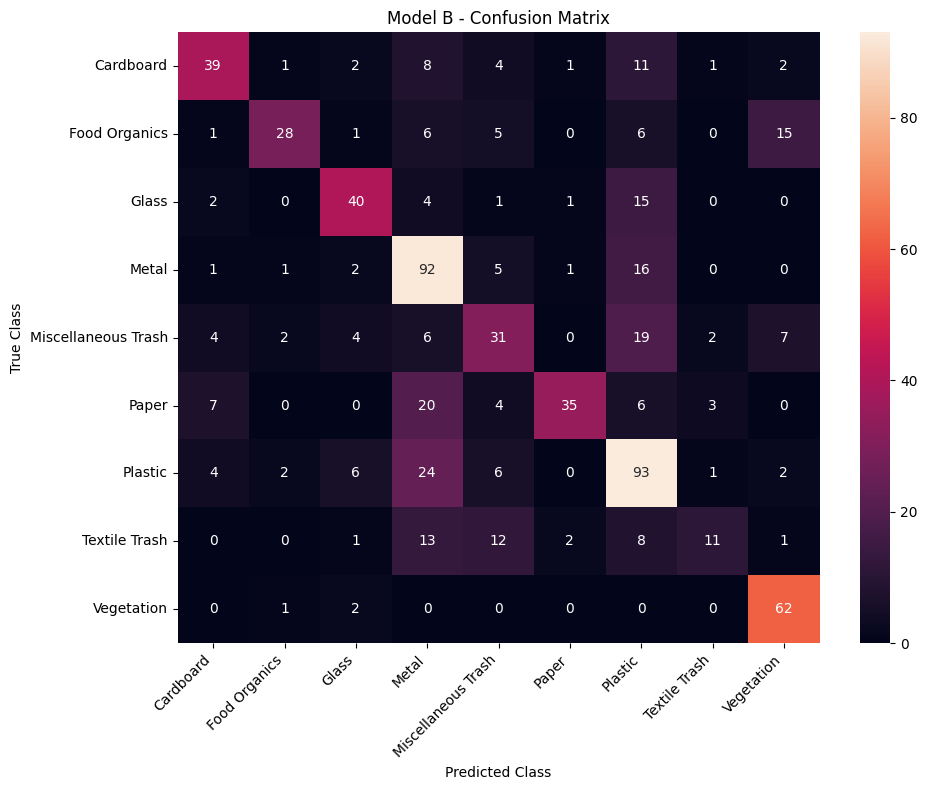

In [51]:
plot_confusion_matrix(
    y_true_b,
    y_pred_b,
    "Model B - Confusion Matrix"
)

##Final comparison table

In [52]:

import pandas as pd

comparison = pd.DataFrame({
    "Metric": [
        "Test Loss",
        "Test Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "Trainable Parameters",
        "Training Time (s)"
    ],
    "Model A": [
        test_loss_a,
        accuracy_a,
        precision_a,
        recall_a,
        f1_a,
        286377,
        training_time_a
    ],
    "Model B": [
        test_loss_b,
        accuracy_b,
        precision_b,
        recall_b,
        f1_b,
        64617,
        training_time_b
    ]
})

comparison


,Metric,Model A,Model B
0,Test Loss,1.412239,1.419549
1,Test Accuracy,0.645161,0.604488
2,Precision,0.652724,0.631676
3,Recall,0.645161,0.604488
4,F1-score,0.642180,0.593566
5,Trainable Parameters,286377.000000,64617.000000
6,Training Time (s),561.372622,708.882573
